<a href="https://colab.research.google.com/github/oooinr4018-web/-1/blob/main/ESAA_1106_%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5.2. 합성곱 신경망 맛보기

fashion_mnist 데이터셋으로 합성곱 신경망 구현

- fashion_mnist 데이터셋

토치비전에 내장된 예제 데이터

운동화, 셔츠, 샌들같은 작은 이미지의 모음

열 가지로 분류될 수 있는 28 X 28 픽셀의 이미지 7만 개로 구성

훈련 데이터 - 0 ~ 255 사이의 값을 갖는 28 X 28 크기의 넘파이 배열

레이블 데이터 - 0 ~ 9까지의 정수 값(운동화, 셔츠 등의 이미지의 클래스를 나타냄) 배열



In [1]:
# 5-1. 라이브러리 호출

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용하는 라이브러리
from torch.utils.data import Dataset, DataLoader

- 파이토치는 GPU 사용을 권장

(GPU가 장착되지 않은 환경에서도 파이토치 실행 가능)

(GPU가 장착되어 있고, GPU 사용 가능 설정이 된다면, 파이토치에서 자동 인식)

(GPU를 설정하지 않은 환경에서는 CPU 사용)

In [2]:
# 코드 5-2. CPU 혹은 GPU 장치 확인
device=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


- GPU 사용 코드

device=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model=Net()
model.to(device)

- 해당 PC에서 다수의 GPU 사용 시 코드

(nn.DataParallel 이용 / 배치 크기가 알아서 각 GPU로 분배되는 방식 / GPU 수만큼 배치 크기 늘려야함.)

device=torch.device("cuda" if torch.duca.is_available() else "cpu")
model=Net()
if torch.cuda.device_count() > 1:
    model=nn.DataParallel(net)
model.to(device)



In [3]:
# 코드 5-3. fasion_mnist 데이터셋 내려받기
train_dataset=torchvision.datasets.FashionMNIST("../chap05/data", download=True,
                                                transform=transforms.Compose([transforms.ToTensor()]))
test_dataset=torchvision.datasets.FashionMNIST("../chap05/data", download=True,
                                               train=False, transform=transforms.Compose([transforms.ToTensor()]))


100%|██████████| 26.4M/26.4M [00:02<00:00, 9.49MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 135kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.57MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.6MB/s]


- torchvision.datasets

torch.utils.data.Dataset의 하위클래스

데이터셋 CIFAR, COCO, MNIST, ImageNet 등 포함

torchvision.datasets.FashionMNIST(...)

첫 번째 파라미터: FashionMNIST를 내려받을 위치 지정 / ../chap05/data 폴더 하위의 FashionMNIST 폴더

download=True: 첫 번째 파라미터의 위치에 해당 데이터셋이 있는지 확인 후 다운로드

transform: 이미지를 텐서(0~1)로 변경



In [4]:
# 코드 5-4. fasion_mnist 데이터를 데이터로더에 전달 (메모리로 불러오기위해)

train_loader=torch.utils.data.DataLoader(train_dataset, batch_size=100)
test_loader=torch.utils.data.DataLoader(test_dataset, batch_size=100)

- torch.utils.data.DataLoader()로 원하는 크기의 배치 단위로 데이터를 불러오거나, 순서가 무작위로 섞이도록(shuffle) 함.

torch.utils.data.DataLoader(...)

첫 번째 파라미터: 데이터를 불러올 데이터셋 지정

batch_size: 데이터를 배치로 묶어줌.

ex) batch_size=100: 100개 단위로 데이터 묶어서 불러옴.

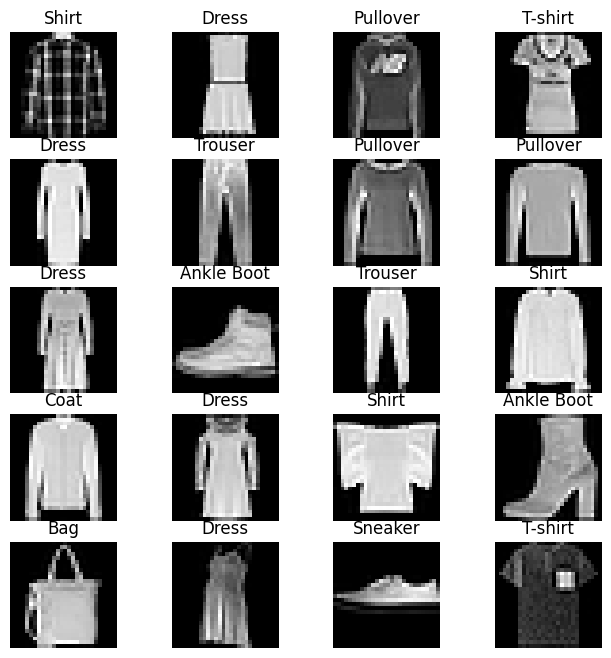

In [7]:
# 코드 5-5. 분류에 사용될 클래스 정의
labels_map={0 : 'T-shirt', 1 : 'Trouser', 2 : 'Pullover', 3 : 'Dress', 4 : 'Coat',
            5 : 'Sandal', 6 : 'Shirt', 7 : 'Sneaker', 8 : 'Bag', 9 : 'Ankle Boot'} # 열 개의 클래스
fig=plt.figure(figsize=(8,8)); # 출력할 이미지의 가로세로 길이로 단위는 inch
columns=4;
rows=5;
for i in range(1, columns*rows+1):
  img_xy=np.random.randint(len(train_dataset));
  img=train_dataset[img_xy][0][0,:,:]
  fig.add_subplot(rows, columns, i)
  plt.title(labels_map[train_dataset[img_xy][1]])
  plt.axis('off')
  plt.imshow(img, cmap='gray')
plt.show() # 20개의 이미지 데이터를 시각적으로 표현


- np.random

무작위로 데이터 생성 시 사용

- np.random.randient()

이산형 분포를 갖는 데이터에서 무작위 표본 추출 시 사용

random.randint(len(train_dataset)): 0~(train_dataset의 길이) 값을 갖는 분포에서 랜덤 숫자 1개 생성

ex)

np.random.randint(10) # 0~10의 임의의 숫자를 출력

np.random.randint(1, 10) # 1~9의 임의의 숫자를 출력

np.random.rand(8) # 0~1 사이의 정규표준분포 난수를 행렬로 (1x8) 출력

np.random.rand(4,2) # 0~1 사이의 정규표준분포 난수를 행렬로 (4x2) 출력

np.random.randn(8) # 평균이 0, 표준편차가 1인 가우시안 정규분포 난수를 행렬로 (1x8) 출력

np.random.randn(4, 2) # 평균이 0, 표준편차가 1인 가우시안 정규분포 난수를 행렬로 (4x2) 출력

- train_dataset으로 3차원 배열 생성

examp=np.arange(0, 100, 3) # 1~99의 숫자에서 3씩 건너뛴 행렬 생성

examp.resize(6, 4) # 행렬의 크기를 6x4로 조정

examp[3] # 3행에 해당하는 모든 요소(값)들을 출력 (행과 열은 0부터 시작)

examp[3, 3] # 3행의 3번째 열에 대한 값 출력

examp[3][3] # 3행의 3번째 열에 대한 값 출력

train_dataset[img_xy][0][0,:,:]: train_dataset에서 [img_xy][0][0,:,:]에 해당하는 요소 값 가져오기





In [15]:
# 코드 5-6. 심층 신경망 모델 생성
# ConvNet이 적용되지 않은 네트워크 생성

class FashionDNN(nn.Module):
  def __init__(self):
    super(FashionDNN, self).__init__()
    self.fc1=nn.Linear(in_features=784, out_features=256)
    self.drop=nn.Dropout(0.25)
    self.fc2=nn.Linear(in_features=256, out_features=128)
    self.fc3=nn.Linear(in_features=128, out_features=10)

  def forward(self, input_data):
    out=input_data.view(-1, 784)
    out=F.relu(self.fc1(out))
    out=self.drop(out)
    out=F.relu(self.fc2(out))
    out=self.fc3(out)
    return out

- 클래스 형태의 모델: torch.nn.Module 상속받음.

- __init__(): 객체가 갖는 속성 값 초기화

(객체 생성 시 자동 호출)

- super(FahsionDNN, self).__init__(): nn.Module 클래스 상속받음.

- C++에서 사용하는 객체 지향 프로그램의 특징들을 파이토치에서 사용. - 대표적인 예시: 객체

객체 지향 프로그램: 프로그래밍에서 필요한 데이터를 추상화하여 속성, 행동, 동작, 특징 등을 객체로 만들고, 그 객체들이 서로 유기적으로 동작하도록 하는 프로그래밍 방법

ex) 자동차 클래스 속 자동차 객체(초록색 대우 디젤, 빨간색 기아 가솔린, 파란색 현대 전기)

객체: 메모리를 할당받아 프로그램에서 사용되는 모든 데이터

객체명=클래스명()

- 함수: 하나의 특정 작업을 수행하기 위해 독립적으로 설계된 프로그램 코드

: 특정 작업만 수행, 결괏값을 계속 사용하기 위해서는 반드시 어딘가에 값을 지정

: 함수 포함 프로그램 코드 재사용 시, 해당 함수, 데이터가 저장되는 변수까지 모두 관리

def add(num1, num2) # 함수 정의(num1, num2를 받아서 더해주는 함수)

def __init__(self) # 객체 생성 시 호출하면 실행되는 초기화 함수

- 클래스: 함수, 변수까지 한꺼번에 묶어서 관리, 재사용할 수 있게 해 주는 것

- nn: 딥러닝 모델 구성에 필요한 모듈이 모여 있는 패키지

nn.Linear(...): 단순 선형 회귀 모델 생성 시 사용

첫 번째 파라미터: in_features (입력의 크기)

두 번째 파라미터: out_features (출력의 크기)

forward() 부분에 첫 번째 파라미터 값 넘겨줌. 두 번째 파라미터에서 정의된 크기가 forward() 연산의 결과.

- torch.nn.Dropout(p): p만큼의 비율로 텐서의 값이 0, 0이 되지 않는 값들은 기존 값 x (1/(1-p))만큼 커짐.

ex) p=0.3: 전체 값 중 0.3의 확률로 0, 0이 되지 않는 값들(0.7의 비율)은 (1/(1-0.3))만큼 커짐.

- forward(): 모델이 학습 데이터를 입력받아 순전파 연산 진행 함수

: 객체, 데이터와 함께 호출 시 자동 실행

*순전파 연산: H(x)^2 식에 입력 x로부터 예측된 y를 얻는 것

H(x)=sigmoid(x1*w1+x2*w2+b)

- 뷰(view): 텐서의 크기 변경 역할

ex) input_data.view(-1, 784): input_data를 (7, 784) 크기로 변경 / 2차원 텐서로 변경하되 (7, 784) 크기로 변경

첫 번째 차원(-1): 사용자가 파이토치에 맡기겠다는 의미

두 번째 차원(784): 차원의 길이가 784

- 활성화 함수 지정

(1) F.relu(): forward() 함수에서 정의

(2) nn.RELU(): __init__() 함수에서 정의



In [16]:
# nn 사용 코드
import torch
import torch.nn as nn

inputs=torch.randn(64, 3, 244, 244)
conv=nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
# 3개의 채널이 입력되어 64개의 채널이 출력되기 위한 연산으로 3x3 크기의 커널을 사용
outputs=conv(inputs)
layer=nn.Conv2d(1, 1, 3)

In [17]:
# nn.functional 사용 코드
import torch.nn.functional as F

inputs=torch.randn(64, 3, 244, 244)
weight=torch.randn(64, 3, 3, 3)
bias=torch.randn(64)
outputs=F.conv2d(inputs, weight, bias, padding=1)

- nn.conv2d(...): input_chanel, output_channel 사용해서 연산 진행

- functional.conv2d(...): input, weight(가중치, 전달할 때마다 가중치 값 새로 정의)



- nn.xx

형태

: nn.Conv2d: 클래스

: nn.Module 클래스를 상속받아 사용

호출 방법

: 하이퍼파라미터 전달 후 함수 호출 -> 데이터 전달

위치

: nn.Sequential 내에 위치

파라미터

: 새로 정의할 필요 X

- nn.functional.xx

형태

: nn.functional.conv2d: 함수

: def function (input)으로 정의된 함수

호출 방법

: 함수 호출 시 하이퍼파라미터, 데이터 전달

위치

: nn.Sequential에 위치 X

파라미터

: 가중치를 수동으로 전달해야 할 때마다 자체 가중치 정의

In [18]:
# 코드 5-7. 심층 신경망에서 필요한 파라미터 정의
# 모델 학습 전, 손실 함수, 학습률, 옵티마이저 정의

learning_rate=0.001;
model=FashionDNN();
model.to(device)

criterion=nn.CrossEntropyLoss(); # 분류 문제에서 사용하는 손실 함수
optimizer=torch.optim.Adam(model.parameters(), lr=learning_rate);
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


- 옵티마이저를 위한 경사 하강법: Adam 사용

- 학습률 lr 0.001 사용

- 이를 통해 심층 신경망 모델 생성

In [33]:
# 코드 5-8. 심층 신경망을 이용한 모델 학습
# 심층 신경망에 데이터 적용하여 모델 학습
num_epochs=5
count=0
loss_list=[]
iteration_list=[]
accuracy_list=[]

predictions_list=[]
labels_list=[]

for epoch in range(num_epochs):
  for images, labels in train_loader:
    images, labels=images.to(device), labels.to(device)

    train=Variable(images.view(100, 1, 28, 28))
    labels=Variable(labels)

    outputs=model(train) # 학습 데이터를 모델에 적용
    loss=criterion(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    count+=1

    if not (count%50): # count를 50으로 나누었을 때 나머지가 0이 아니라면 실행
      total=0
      correct=0
      for images, labels in test_loader:
        images, labels=images.to(device), labels.to(device)
        labels_list.append(labels)
        test=Variable(images.view(100, 1, 28, 28))
        outputs=model(test)
        predictions=torch.max(outputs, 1)[1].to(device)
        predictions_list.append(predictions)
        correct+=(predictions==labels).sum()
        total+=len(labels)

      accuracy=correct*100/total
      loss_list.append(loss.data)
      iteration_list.append(count)
      accuracy_list.append(accuracy)

  if not (count%500):
    print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data,
                                                          accuracy))

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 2-D input to dropout2d, which is deprecated and will result in an error in a future release. To retain the behavior and silence this warning, please use dropout instead. Note that dropout2d exists to provide channel-wise dropout on inputs with 2 spatial dimensions, a channel dimension, and an optional batch dimension (i.e. 3D or 4D inputs).
  return F.dropout2d(input, self.p, self.training, self.inplace)


Iteration: 3000, Loss: 0.19222858548164368, Accuracy: 90.38999938964844%


- 리스트(배열, 행렬) 사용 방법

비어 있는 배열, 행렬 만들기

append 메서드로 데이터 하나씩 추가

- for 구문으로 레코드(행, 가로줄) 하나씩 가져오기

ex) for x, y in train: in 앞 변수 지정 시, 레코드에서 요소 2개 꺼내오기

- 모델이 데이터를 처리하기 위해서는, 모델, 데이터가 동일한 장치(CPU or GPU)에 위치

ex) model.to(device) - GPU 사용

-> images.to(device), labels.to(device) - GPU 사용

- Autograd: 자동 미분 수행 파이토치 핵심 해키지

테이프(tape): 자동 미분에 대한 값 저장

순전파 단계: 수행하는 모든 연산 저장

역전파 단계: 저장된 값들 꺼내서 사용

Variable: 역전파 위한 미분 값 자동 계산

(torch.autograd 패키지 안 Variable 이용 시, 자동 미분 계산)

- 분류 문제에 대한 정확도는 전체 예측에 대한 정확한 예측의 비율로 표현

코드: classification accuracy = correct predictions / total predictions

백분율 코드: classification accuracy = correct predictions 'total predictions * 100

오분류율(오류율)

코드: error rate = (1- (correct predictions / total predictions)) * 100

- 분류 문제에서 클래스가 3개 이상인 경우 주의사항

(1) 정확도가 80% 이상인 경우

80% 값이 모든 클래스가 동등하게 고려된 것인지, 특정 클래스의 분류가 높았던 것인지 알 수 없음에 유의.

(2) 정확도가 90% 이상이니 경우

90% 해당 데이터가 하나의 클래스에 속할 경우 90%의 정확도는 높다고 볼 수 X.



In [31]:
# 코드 5-9. 합성곱 네트워크 생성
class FashionCNN(nn.Module):
  def __init__(self):
    super(FashionCNN, self).__init__()
    self.layer1=nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)
    )
    self.layer2=nn.Sequential(
        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2)
    )
    self.fc1=nn.Linear(in_features=64*6*6, out_features=600)
    self.drop=nn.Dropout2d(0.25)
    self.fc2=nn.Linear(in_features=600, out_features=120)
    self.fc3=nn.Linear(in_features=120, out_features=10) # 마지막 계층의 out_features는 클래스 개수를 의미
  def forward(self, x):
    out=self.layer1(x)
    out=self.layer2(out)
    out=out.view(out.size(0), -1)
    out=self.fc1(out) # 첫 번째 완전연결층을 통과
    out=self.drop(out) # 일부 뉴런의 출력을 무작위로 0으로 만듦
    out=self.fc2(out) # 드롭아웃이 적용된 데이터를 다음 층으로 전달
    out=self.fc3(out)
    return out

- nn.Sequential: __init__()에서 사용할 네트워크 모델들 정의

: forward() 함수에서 구현될 순전파를 계층 형태로 가독성 좋은 코드로 작성

: 계층을 차례로 쌓을 수 있도록 수식(Wx+b), 활성화 함수 연결

- 합성곱층: 합성곱 연산을 통해 이미지 특징 추출

합성곱: 커널(nxm 크기의 행렬)이 높이x너비 크기의 이미지 처음부터 끝까지 훑으며 각 원소 값끼리 곱한 후 모두 더한 값 출력

nn.Conv2d(...)

첫 번째 파라미터: in_channels (입력 채널 수)

흑백 이미지는 1, RGB 값 이미지는 3

흑백 이미지 - wxh 형태의 행렬

컬러 이미지 - wxhxc 형태의 행렬

Red, Green, Blue 3개의 채널

두 번째 파라미터: out_channels (출력 채널 수)

세 번째 파라미터: kernel_size (커널 크기(필터))

커널: 이미지 특징을 찾아내기 위한 공용 파라미터

: 입력 데이터를 스트라이드 간격으로 순화하며 합성곱 계산

CNN 학습 대상: 필터 파라미터

네 번째 파라미터: papdding (패딩 크기) (출력 크기 조정하기 위해 데이터 주위 0으로 채움.)

- BatchNorm2d: 각 배치 단위별로 데이터가 다양한 분포를 가지더라도 평균, 분산을 이용하여 정규화

: 평균 0, 표준편차 1로 데이터 분포 조정

- MaxPool2d: 이미지 크기 축소

풀링 계층: 입력(합성곱층의 출력 데이터)에서 출력 데이터의 크기를 줄이거나, 특정 데이터 강조

: nn.MaxPool2d(kernel_size = ?, stride = ?)

처리 방법

(1) 최대 풀링

(2) 평균 풀링

(3) 최소 풀링

- kernel_size: mxn 행렬로 구성된 가중치

- stride: 입력 데이터에 커널 적용 시 이동할 간격

: stride 값이 커지면 출력 크기는 작아짐.

- 클래스 분류를 위해 이미지 형태의 배열을 배열 형태로 변환

Conv2d의 하이퍼파라미터 값(패딩, 스트라이드)에 따라 출력 크기가 달라짐.

-> 출력 크기는 완전연결층(분류 담당)으로 전달

- in_features: 입력 데이터의 크기

Conv2d, MaxPool2d에서의 입력(이미지 데이터) -> 출력 결과를 완전연결층으로 보냄.(1차원으로 변경하는 과정 필요)

(1) Conv2d 계층에서늬 출력 크기 구하는 공식

출력 크기 = (W-F+2P)/S + 1

(2) MaxPool2d 계층에서의 출력 크기 구하는 공식

출력 크기 = IF(입력 필터의 크기) / F(커널 크기)

- 합성곱층에서 완전연결층으로 변경 (데이터 형태 1차원으로 변환)

out.size(0): (100.?) 크기의 텐서로 변경

out.view(out.size(0), -1): 행의 수 정확히 알고 있지만, 열의 수 알지 못할 때



In [32]:
# 코드 5-10. 합성곱 네트워크를 위한 파라미터 정의
learning_rate=0.001;
model=FashionCNN();
model.to(device)

criterion=nn.CrossEntropyLoss();
optimizer=torch.optim.Adam(model.parameters(), lr=learning_rate);
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout2d(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [37]:
# 코드 5-11. 모델 학습 및 성능 평가
# 학습 데이터를 이용한 모델 학습

num_epochs=5
count=0
loss_list=[]
iteration_list=[]
accuracy_list=[]

predictions_list=[]
labels_list=[]

for epoch in range(num_epochs):
  for images, labels in train_loader:
    images, labels=images.to(device), labels.to(device)

    train=Variable(images.view(100, 1, 28, 28))
    labels=Variable(labels)

    outputs=model(train)
    loss=criterion(outputs, labels) # 예측값, 실제 정답 비교하여 손실 계산
    optimizer.zero_grad() # 이전 학습 단계에서 계산된 기울기 초기화
    loss.backward() # 역전파 수행
    optimizer.step() # 가중치 업데이트
    count+=1

    if not (count % 50):
      total=0
      correct=0
      for images, labels in test_loader:
        images, labels=images.to(device), labels.to(device)
        labels_list.append(labels)
        test=Variable(images.view(100, 1, 28, 28))
        outputs=model(test)
        predictions=torch.max(outputs, 1)[1].to(device)
        predictions_list.append(predictions)
        correct+=(predictions==labels).sum()
        total+=len(labels)

      accuracy=correct*100/total
      loss_list.append(loss.data)
      iteration_list.append(count)
      accuracy_list.append(accuracy)

    if not (count%500):
      print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data,accuracy))

Iteration: 500, Loss: 0.14066475629806519, Accuracy: 90.73999786376953%
Iteration: 1000, Loss: 0.11958731710910797, Accuracy: 90.23999786376953%
Iteration: 1500, Loss: 0.13979807496070862, Accuracy: 89.44999694824219%
Iteration: 2000, Loss: 0.14299376308918, Accuracy: 89.30999755859375%
Iteration: 2500, Loss: 0.0380299836397171, Accuracy: 90.63999938964844%
Iteration: 3000, Loss: 0.15336324274539948, Accuracy: 89.62000274658203%


- 심층 신경망과 비교하였을 떄, 정확도가 약간 더 높음.

- 이미지 데이터가 많아지면, 단순 심층 신경망으로는 정확한 특성 추출, 분류 불가능

-> 합성곱 신경망으로 학습